Guide:
YRS = years played
G = games played
AB = at bats
R = runs
H = hits
2B = doubles
3B = triples
HR = home runs
RBI = rbis?
BB = walks
SO = strike outs
SB = stolen bases
CS = caught stealing
BA = batting average
HOF = hall of fame (yes or no)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

In [2]:
df = pd.read_csv('500hits.csv', encoding='latin-1')
df

,PLAYER,YRS,G,AB,R,H,2B,3B,HR,RBI,BB,SO,SB,CS,BA,HOF
0,Ty Cobb,24,3035,11434,2246,4189,724,295,117,726,1249,357,892,178,0.366,1
1,Stan Musial,22,3026,10972,1949,3630,725,177,475,1951,1599,696,78,31,0.331,1
2,Tris Speaker,22,2789,10195,1882,3514,792,222,117,724,1381,220,432,129,0.345,1
3,Derek Jeter,20,2747,11195,1923,3465,544,66,260,1311,1082,1840,358,97,0.310,1
4,Honus Wagner,21,2792,10430,1736,3430,640,252,101,0,963,327,722,15,0.329,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
460,Jim Wynn,15,1920,6653,1105,1665,285,39,291,964,1224,1427,225,101,0.250,0
461,Jorge Posada,17,1829,6092,900,1664,379,10,275,1065,936,1453,20,21,0.273,0
462,Brady Anderson,15,1834,6499,1062,1661,338,67,210,761,960,1190,315,100,0.256,0
463,Cookie Rojas,16,1822,6309,714,1660,254,25,54,593,396,489,74,68,0.263,0


In [3]:
df = df.drop(columns=['PLAYER', 'CS'])
df

,YRS,G,AB,R,H,2B,3B,HR,RBI,BB,SO,SB,BA,HOF
0,24,3035,11434,2246,4189,724,295,117,726,1249,357,892,0.366,1
1,22,3026,10972,1949,3630,725,177,475,1951,1599,696,78,0.331,1
2,22,2789,10195,1882,3514,792,222,117,724,1381,220,432,0.345,1
3,20,2747,11195,1923,3465,544,66,260,1311,1082,1840,358,0.310,1
4,21,2792,10430,1736,3430,640,252,101,0,963,327,722,0.329,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
460,15,1920,6653,1105,1665,285,39,291,964,1224,1427,225,0.250,0
461,17,1829,6092,900,1664,379,10,275,1065,936,1453,20,0.273,0
462,15,1834,6499,1062,1661,338,67,210,761,960,1190,315,0.256,0
463,16,1822,6309,714,1660,254,25,54,593,396,489,74,0.263,0


In [4]:
x = df.iloc[:,0:13]
y = df.iloc[:,13]
print(x)
print(y)

     YRS     G     AB     R     H   2B   3B   HR   RBI    BB    SO   SB     BA
0     24  3035  11434  2246  4189  724  295  117   726  1249   357  892  0.366
1     22  3026  10972  1949  3630  725  177  475  1951  1599   696   78  0.331
2     22  2789  10195  1882  3514  792  222  117   724  1381   220  432  0.345
3     20  2747  11195  1923  3465  544   66  260  1311  1082  1840  358  0.310
4     21  2792  10430  1736  3430  640  252  101     0   963   327  722  0.329
..   ...   ...    ...   ...   ...  ...  ...  ...   ...   ...   ...  ...    ...
460   15  1920   6653  1105  1665  285   39  291   964  1224  1427  225  0.250
461   17  1829   6092   900  1664  379   10  275  1065   936  1453   20  0.273
462   15  1834   6499  1062  1661  338   67  210   761   960  1190  315  0.256
463   16  1822   6309   714  1660  254   25   54   593   396   489   74  0.263
464   15  1468   5629   785  1660  247   71   61   499   266   471  267  0.295

[465 rows x 13 columns]
0      1
1      1
2      1


In [5]:
x_train, x_test, y_train, y_test = train_test_split(x, y, random_state=11, test_size=0.2)

In [6]:
scaler = MinMaxScaler(feature_range=(0,1))

In [7]:
x_train = scaler.fit_transform(x_train)
x_test = scaler.fit_transform(x_test)
print(x_train)
print(x_test)

[[0.46666667 0.35255438 0.31382907 ... 0.67820248 0.00929235 0.225     ]
 [0.13333333 0.25543753 0.24989842 ... 0.18595041 0.17155111 0.38333333]
 [0.2        0.23672231 0.18854124 ... 0.32386364 0.02144389 0.375     ]
 ...
 [0.46666667 0.32169954 0.32263308 ... 0.13429752 0.18656183 0.64166667]
 [0.53333333 0.58523015 0.50684004 ... 0.61260331 0.22444603 0.175     ]
 [0.2        0.21041983 0.16402546 ... 0.41219008 0.02144389 0.3       ]]
[[0.5        0.33425224 0.10288675 ... 0.10147173 0.02853261 0.35869565]
 [0.5        0.44727774 0.30662472 ... 0.38652208 0.06929348 0.32608696]
 [0.28571429 0.452102   0.51720947 ... 0.12083656 0.4986413  1.        ]
 ...
 [0.42857143 0.31219848 0.15173945 ... 0.17893106 0.04076087 0.40217391]
 [0.35714286 0.47553411 0.50943745 ... 0.54531371 0.06793478 0.54347826]
 [0.57142857 0.69676085 0.67246484 ... 0.21068939 0.26766304 0.75      ]]


In [8]:
class KNearestNeighbors:
    def __init__(self, k=3):
        self.k = k
        self.points = None

    def fit(self, x_train, y_train):
        negative = x_train[y_train == 0]
        positive = x_train[y_train == 1]
        self.points = [negative, positive]

    def predict(self, new_point, dist=False):
        distances = []
        
        for i, category in enumerate(self.points):
            for point in category:
                distance = np.sqrt(np.sum((np.array(new_point) - np.array(point))**2))
                distances.append([distance, i])
                
        categories = [point[1] for point in sorted(distances)[:self.k]]
        result = Counter(categories).most_common(1)[0][0]
        if dist:
            furthest_distance = sorted(distances)[self.k-1][0]
            return result, furthest_distance
        else:
            return result

In [9]:
clf = KNearestNeighbors(k=7)
clf.fit(x_train, y_train)

In [10]:
y_pred = []
for x in x_test:
    y_pred.append(clf.predict(x))

In [11]:
sum(y_pred == y_test) / len(y_test)

0.7956989247311828

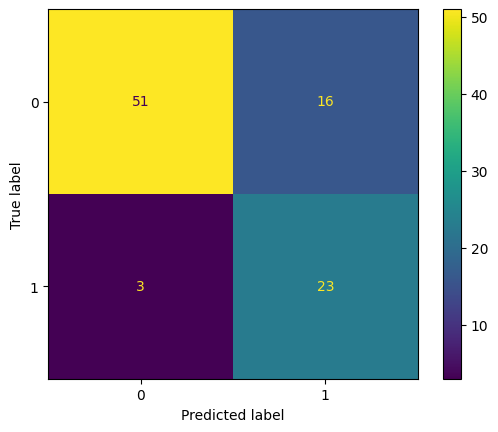

In [12]:
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot()

In [13]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.94      0.76      0.84        67
           1       0.59      0.88      0.71        26

    accuracy                           0.80        93
   macro avg       0.77      0.82      0.78        93
weighted avg       0.85      0.80      0.81        93



In [14]:
# testing on 2d data for visualization
def generate_data(num_samples, scale, cat0_center, cat1_center, seed=42):
    np.random.seed(seed)
    n_cat0 = np.random.randint(num_samples // 10, num_samples * 9 // 10)
    n_cat1 = num_samples - n_cat0

    cat0_xpoints = np.random.normal(loc=cat0_center[0], scale=scale, size=(n_cat0, 1))
    cat0_ypoints = np.random.normal(loc=cat0_center[1], scale=scale, size=(n_cat0, 1))
    cat0_points = np.hstack((cat0_xpoints, cat0_ypoints))
    cat0_labels = np.zeros(n_cat0)
    
    cat1_xpoints = np.random.normal(loc=cat1_center[0], scale=scale, size=(n_cat1, 1))
    cat1_ypoints = np.random.normal(loc=cat1_center[1], scale=scale, size=(n_cat1, 1))
    cat1_points = np.hstack((cat1_xpoints, cat1_ypoints))
    cat1_labels = np.ones(n_cat1)
    
    x = np.vstack((cat0_points, cat1_points))
    y = np.concatenate((cat0_labels, cat1_labels))
    
    indices = np.arange(num_samples)
    np.random.shuffle(indices)
    x = x[indices]
    y = y[indices].astype(int)
    return x, y

x_train, y_train = generate_data(num_samples=40, scale=2.0, cat0_center=[2, 6], cat1_center=[6, 2], seed=42)
clf = KNearestNeighbors(k=3)
clf.fit(x_train, y_train)

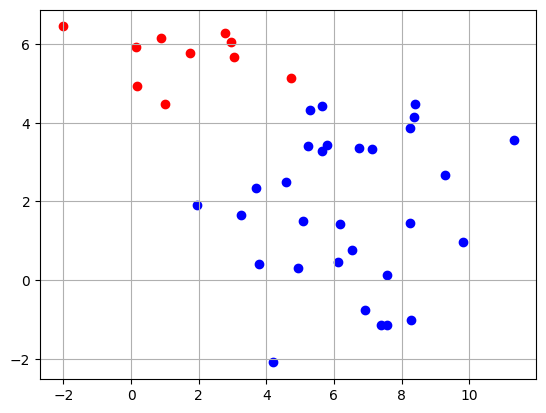

In [15]:
plt.scatter(clf.points[0][:, 0], clf.points[0][:, 1], color='red')
plt.scatter(clf.points[1][:, 0], clf.points[1][:, 1], color='blue')
plt.grid()

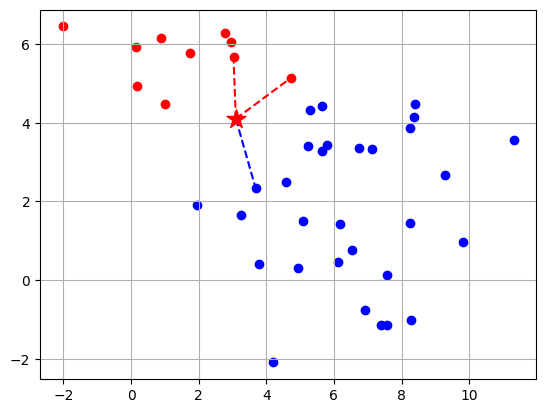

In [16]:
plt.scatter(clf.points[0][:, 0], clf.points[0][:, 1], color='red')
plt.scatter(clf.points[1][:, 0], clf.points[1][:, 1], color='blue')
plt.grid()

new_point = [3.1, 4.1]
new_class, furthest_distance = clf.predict(new_point, dist=True)
color = 'red' if new_class == 0 else 'blue'
plt.scatter(new_point[0], new_point[1], color=color, marker="*", s=200, zorder=100)

for point in clf.points[0]:
    if np.sqrt(np.sum((np.array(new_point) - np.array(point))**2)) <= furthest_distance:
        plt.plot([new_point[0], point[0]], [new_point[1], point[1]], color='red', linestyle='--')
    
for point in clf.points[1]:
    if np.sqrt(np.sum((np.array(new_point) - np.array(point))**2)) <= furthest_distance:
        plt.plot([new_point[0], point[0]], [new_point[1], point[1]], color='blue', linestyle='--')

In [17]:
x_test, y_test = generate_data(num_samples=100, scale=2.0, cat0_center=[2, 6], cat1_center=[6, 2], seed=14)
y_pred = []
for x in x_test:
    y_pred.append(clf.predict(x))
sum(y_pred == y_test) / len(y_test)

0.94

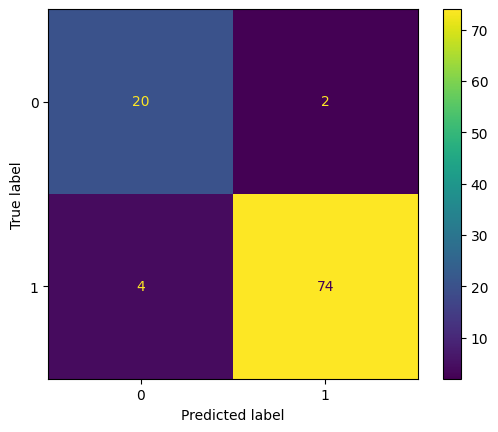

In [18]:
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot()

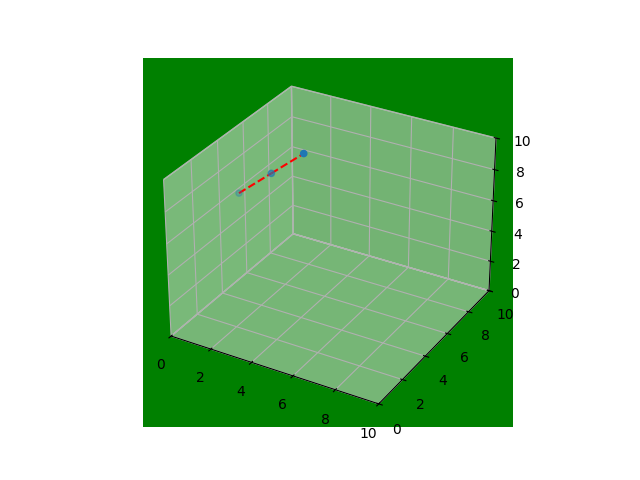

In [22]:
%matplotlib widget
ax = plt.figure().add_subplot(projection='3d')
ax.scatter([1, 2, 3], [4, 5, 6], [7, 8, 9])
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.set_zlim(0, 10)
plt.plot([1,2], [4,5], [7,8], color='red', linestyle='--')
plt.plot([2,3], [5,6], [8,9], color='red', linestyle='--')
ax.set_facecolor("green")